# Эталон мощности ПГУ: исследование данных и моделей

**Задача кейса.** По погоде и параметру оборудования (вакууму) прогнозировать электрическую мощность парогазовой установки и определить, какие параметры влияют сильнее всего.

**Данные.** UCI Machine Learning Repository, датасет 294 «Combined Cycle Power Plant»: 9 568 часовых замеров станции на полной нагрузке за 2006–2011 годы. Лицензия CC BY 4.0.

**Идея решения — эталон станции в двух режимах:**
- **план на завтра** — модель без вакуума (его завтрашнего значения никто не знает): прогноз мощности по прогнозу погоды и риск не выполнить требуемый объём;
- **контроль сейчас** — модель со всеми параметрами: раскладывает недобор мощности на «вакуум» и «прочее».

Вся логика живёт в пакете `powerplant`, ноутбук только вызывает её и показывает результаты.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "powerplant").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from powerplant import config, eda
from powerplant.data import drop_exact_duplicates, glue_sheets, load_raw, load_sheets, validate_contract

pd.set_option("display.precision", 3)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Данные и ловушка с листами

Авторы выложили xlsx с пятью листами. Проверим, что в них лежит.

In [2]:
sheets = load_sheets()
first = next(iter(sheets.values()))
display(pd.DataFrame({"лист": list(sheets), "строк": [len(s) for s in sheets.values()]}))


def normalized(frame: pd.DataFrame) -> pd.DataFrame:
    return frame.round(4).sort_values(list(frame.columns)).reset_index(drop=True)


same_rows = all(normalized(s).equals(normalized(first)) for s in sheets.values())
glued = glue_sheets(sheets)
print(f"Набор строк на всех листах одинаковый: {same_rows}")
print(f"Если склеить листы: {len(glued)} строк, из них уникальных {len(glued.round(4).drop_duplicates())}")

,лист,строк
0,Sheet1,9568
1,Sheet2,9568
2,Sheet3,9568
3,Sheet4,9568
4,Sheet5,9568


Набор строк на всех листах одинаковый: True
Если склеить листы: 47840 строк, из них уникальных 9527


In [3]:
raw = validate_contract(load_raw())
print("csv с сайта совпадает с первым листом строка в строку:", raw.round(4).equals(sheets["Sheet1"].round(4)))

csv с сайта совпадает с первым листом строка в строку: True


**Вывод.** Пять листов — одни и те же 9 568 строк в разном порядке: авторы сделали так для проверки 5×2. Если склеить листы, почти каждая строка проверки окажется и в обучении, и точность выйдет фальшиво высокой. Берём один экземпляр — `data.csv` с сайта UCI, он совпадает с первым листом.

## 2. Разведочный анализ

### 2.1 Качество данных

In [4]:
q = eda.quality_report(raw)
display(pd.DataFrame({
    "показатель": ["строк", "пропусков", "точных дублей", "конфликтов «тот же вход — другая мощность»",
                   "строк с RH > 100 %", "значений вне контракта"],
    "значение": [q.rows, sum(q.missing.values()), q.duplicates, q.conflicts,
                 q.humidity_over_100, sum(q.out_of_contract.values())],
}))
df = drop_exact_duplicates(raw)
print(f"После удаления дублей: {len(df)} строк")
display(eda.describe_with_shape(df).round(2))

,показатель,значение
0,строк,9568
1,пропусков,0
2,точных дублей,41
3,конфликтов «тот же вход — другая мощность»,0
4,строк с RH > 100 %,55
5,значений вне контракта,0


После удаления дублей: 9527 строк


,count,mean,std,min,25%,50%,75%,max,IQR,асимметрия
AT,9527.0,19.66,7.44,1.81,13.53,20.35,25.71,37.11,12.18,-0.14
V,9527.0,54.29,12.69,25.36,41.74,52.08,66.51,81.56,24.77,0.20
AP,9527.0,1013.24,5.94,992.89,1009.08,1012.92,1017.20,1033.30,8.12,0.27
RH,9527.0,73.33,14.61,25.56,63.38,75.00,84.85,100.16,21.47,-0.44
PE,9527.0,454.34,17.04,420.26,439.75,451.52,468.36,495.76,28.62,0.31


- 41 точный дубль удаляем до разбиения. Пропусков нет, все значения укладываются в контракт.
- Влажность до 100.16 % — огрех датчика на доли процента, строки оставляем.

### 2.2 Распределения и выбросы

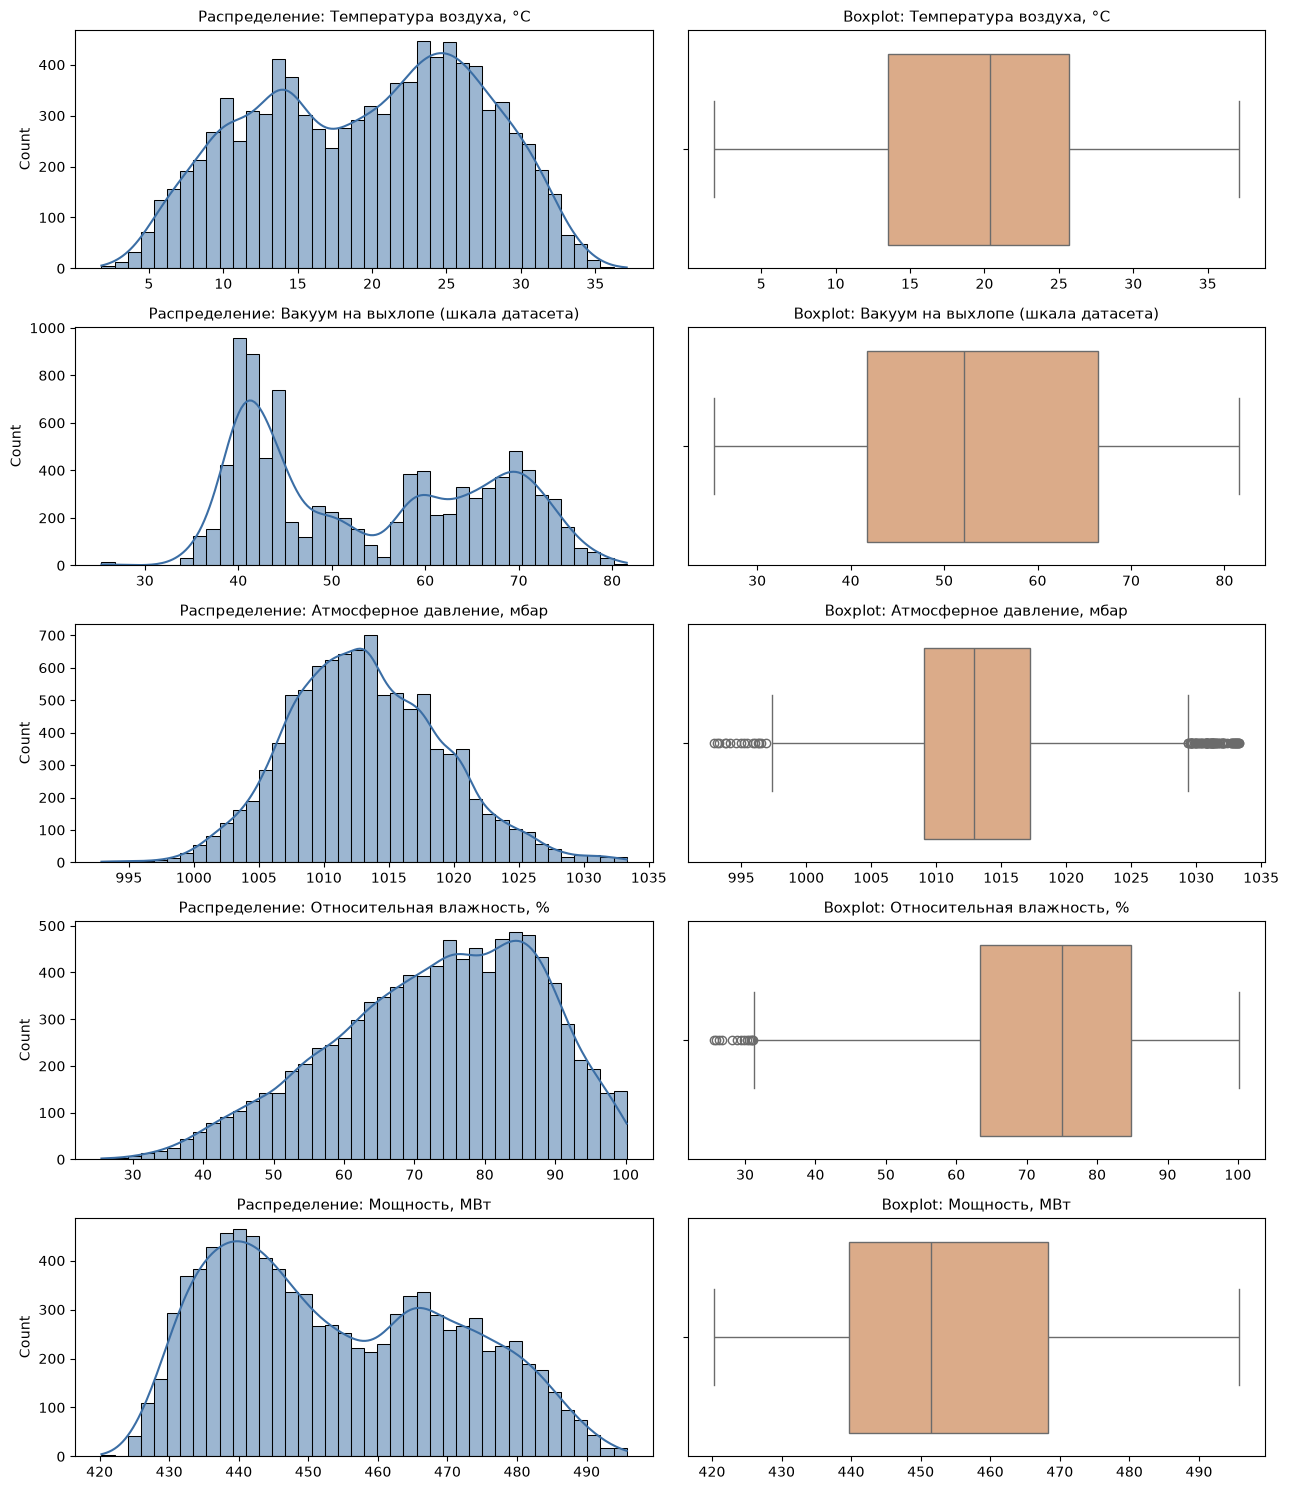

In [5]:
fig = eda.plot_distributions(df)
save(fig, "eda_distributions")
plt.show()

In [6]:
display(eda.iqr_outliers(df).to_frame())
modes = {col: [round(m, 1) for m in eda.histogram_modes(df[col])] for col in df.columns}
display(pd.Series(modes, name="центры мод").to_frame())

,выбросов по IQR
AT,0
V,0
AP,91
RH,13
PE,0


,центры мод
AT,"[14.2, 24.8]"
V,"[41.3, 50.7, 61.9, 69.4]"
AP,[1012.4]
RH,[84.0]
PE,"[439.1, 466.8]"


- **У мощности две моды** (около 439 и 467 МВт), у температуры две, у вакуума несколько. Разбиение стратифицируем по мощности, чтобы обе моды попали в тест в той же доле, что и в обучение.
- Причину мод (сезоны?) по этим данным проверить нельзя: времени в строках нет. Это гипотеза, а не факт.
- Асимметрия всех колонок меньше 0.5 по модулю: преобразования распределений не нужны.
- Выбросы по правилу IQR есть только у давления (91) и влажности (13). Это реальная погода, а не ошибки, — оставляем.

### 2.3 Связи с мощностью

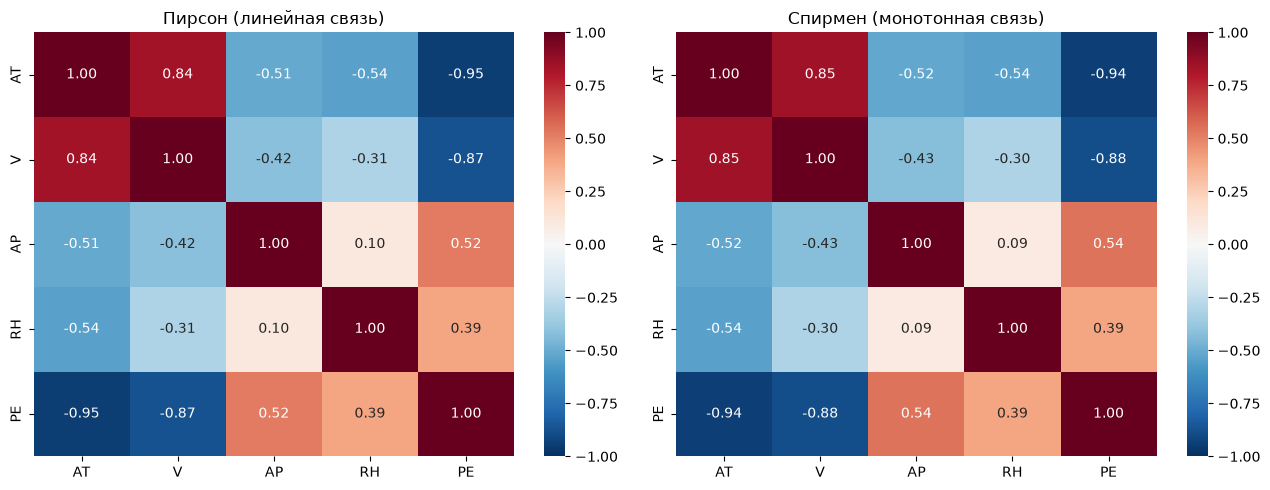

In [7]:
pearson, spearman = eda.correlation_tables(df)
fig = eda.plot_correlations(pearson, spearman)
save(fig, "eda_correlations")
plt.show()

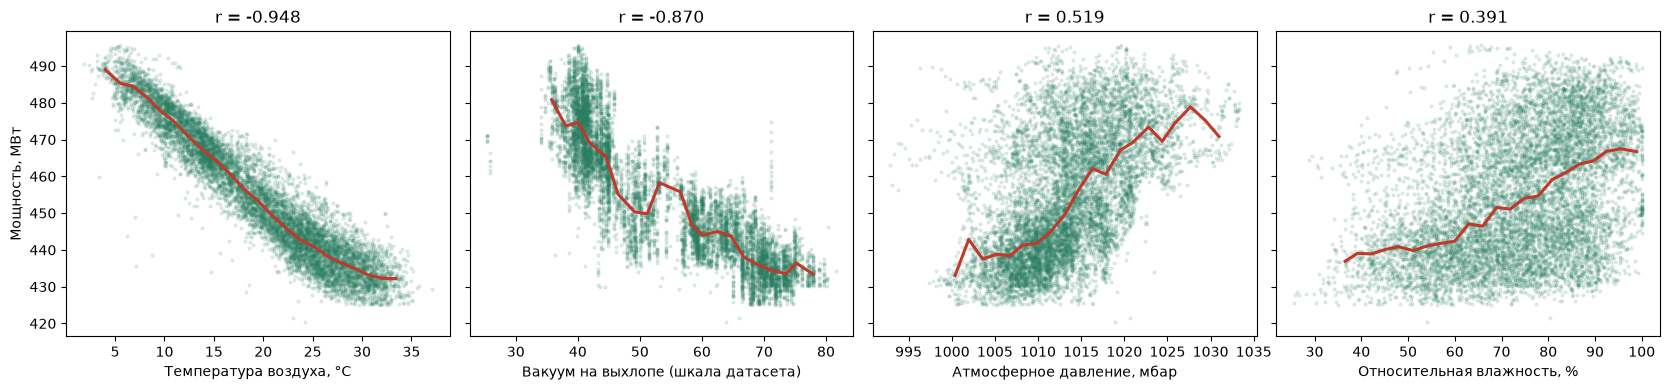

In [8]:
fig = eda.plot_target_relations(df, list(config.FEATURES_ALL))
save(fig, "eda_target_relations")
plt.show()

In [9]:
from sklearn.linear_model import LinearRegression

x_lin = df[["AT"]]
x_sq = df[["AT"]].assign(AT2=df["AT"] ** 2)
r2_lin = LinearRegression().fit(x_lin, df["PE"]).score(x_lin, df["PE"])
r2_sq = LinearRegression().fit(x_sq, df["PE"]).score(x_sq, df["PE"])
print(f"R² мощности от одной температуры: линейная {r2_lin:.4f}, с квадратом AT {r2_sq:.4f}")

R² мощности от одной температуры: линейная 0.8985, с квадратом AT 0.9067


- Одна температура объясняет около 90 % разброса мощности (R² ≈ 0.90).
- Связь слегка нелинейная: красная кривая медиан изгибается, квадрат температуры добавляет R². Поэтому в лестнице моделей есть полином и бустинг.
- Спирмен почти совпадает с Пирсоном: связи монотонные.

### 2.4 Мультиколлинеарность и частные корреляции

In [10]:
display(eda.variance_inflation(df, list(config.FEATURES_ALL)).round(2).to_frame())
partial = pd.DataFrame([
    {
        "признак": col,
        "сырая корреляция с PE": round(df[col].corr(df["PE"]), 3),
        "при фиксированной AT": round(eda.partial_correlation(df, col, "PE", ["AT"]), 3),
    }
    for col in ("V", "AP", "RH")
])
display(partial)

,VIF
AT,5.97
V,3.94
AP,1.45
RH,1.71


,признак,сырая корреляция с PE,при фиксированной AT
0,V,-0.870,-0.410
1,AP,0.519,0.135
2,RH,0.391,-0.466


- AT и V заметно связаны (VIF около 6 и 4). Перестановочная важность по одному признаку при такой связи занижает вклад обоих, поэтому важность считаем и по группе {AT, V}.
- **Влажность меняет знак.** Сырая корреляция с мощностью +0.39, а при фиксированной температуре −0.47. «Плюс» шёл через температуру: влажно бывает, когда холодно. По физике влажный воздух легче сухого, через компрессор проходит меньше массы, и мощность ниже.
- Давление и вакуум сохраняют знак и при фиксированной температуре: у них есть собственный вклад.

### 2.5 Проверка физики знаков

In [11]:
display(eda.physics_sign_check(df))

,признак,ожидаемый знак,корреляция с PE,сходится
0,AT,−,-0.948,True
1,V,−,-0.870,True
2,AP,+,0.519,True


Все знаки сходятся с физикой: жарче → меньше мощность, хуже вакуум → меньше, выше давление → больше.

### 2.6 Покрытие пространства признаков

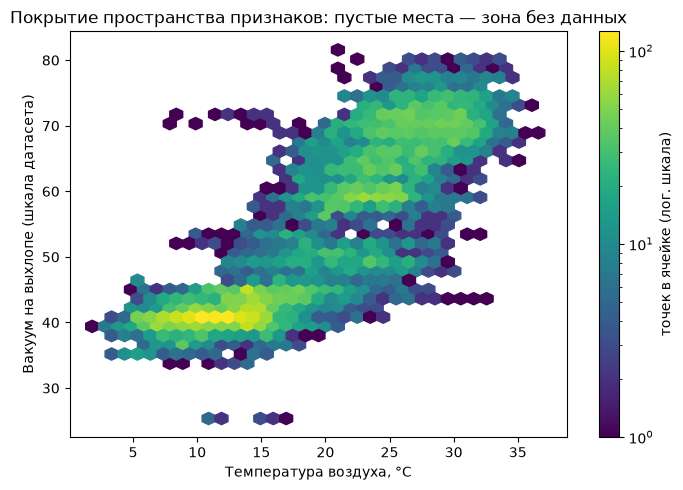

In [12]:
fig = eda.plot_coverage(df, "AT", "V")
save(fig, "eda_coverage_at_v")
plt.show()

In [13]:
for gap in eda.find_gaps(df["V"], min_width=2.0):
    print(f"V: пусто между {gap.low} и {gap.high}; ниже промежутка {gap.count_below} строк")
display(df[df["V"] < 30].describe().loc[["min", "mean", "max"]].round(2))
hot = df[df["AT"] > 30]
print(f"Жарких часов (AT > 30 °C): {len(hot)}, из них с V < 45: {(hot['V'] < 45).sum()}; "
      f"минимальный V в жару: {hot['V'].min()}")

V: пусто между 25.88 и 34.03; ниже промежутка 13 строк


,AT,V,AP,RH,PE
min,10.59,25.36,1008.27,65.47,460.97
mean,13.16,25.60,1009.17,85.04,467.15
max,16.61,25.88,1009.59,100.16,471.19


Жарких часов (AT > 30 °C): 733, из них с V < 45: 3; минимальный V в жару: 43.21


- Отдельный кластер V 25.4–25.9: 13 строк, у всех давление 1008–1010, похоже на один эпизод. Между 25.9 и 34.0 значений нет совсем.
- В жару вакуум всегда «плохой»: при AT > 30 °C значение V не ниже 43.2. Сочетание «жара + низкий V» — зона без данных. Модель там гадает, и страница должна об этом предупреждать.

### 2.7 Журнал решений

In [14]:
journal = (ROOT / "reports" / "decisions.md").read_text(encoding="utf-8")
display(Markdown(journal.split("\n", 1)[1]))


Записи 1–14 сделаны по итогам разведочного анализа, **до** обучения моделей. Записи 15–17 добавлены после первого обучения по кросс-валидации, тест при этом не трогали. Записи 18–22 сделаны после итогового теста, на выбор моделей они не влияли. Цифры воспроизводятся в `notebooks/research.ipynb`, раздел 2.

| # | Находка | Решение |
|---|---|---|
| 1 | В `Folds5x2_pp.xlsx` 5 листов по 9 568 строк — одни и те же строки в разном порядке. Склейка даёт 47 840 строк, уникальных 9 527 | Берём один экземпляр: `data.csv` с UCI, он совпадает с первым листом. Листы не склеиваем |
| 2 | 41 точный дубль, конфликтов «тот же вход — другая мощность» нет | Удаляем дубли до разбиения, остаётся 9 527 строк |
| 3 | Пропусков нет, за границы контракта ничего не выходит | Чистка не нужна |
| 4 | RH больше 100% в 55 строках, максимум 100.16 | Оставляем: огрех датчика до 0.16 п.п., на модель не влияет. API принимает RH от 0 до 100 |
| 5 | По правилу IQR выбросы есть только у AP (91) и RH (13) | Оставляем: это реальная погода, а не ошибка, и в контракт значения укладываются |
| 6 | Асимметрия всех колонок меньше 0.5 по модулю | Преобразования распределений (PowerTransformer и т. п.) не применяем |
| 7 | Связь мощности с AT слегка нелинейная: R² линейной 0.8985, с квадратом AT 0.9067 | В лестнице моделей есть полином и бустинг |
| 8 | AT и V связаны: VIF 5.97 и 3.94, корреляция +0.84 | Важность считаем и по группе {AT, V}, а не только по одному признаку |
| 9 | Сырая корреляция RH с мощностью +0.39, а при фиксированной AT она −0.47 (при фиксированных AT и V −0.39) | «Плюс» влажности идёт через температуру. По физике влажный воздух легче, и мощность ниже. Знак проверяем по графикам частичной зависимости |
| 10 | Знаки AT (−), V (−) и AP (+) сходятся с физикой | Признаки в модели оставляем как есть |
| 11 | У мощности две моды, около 439 и 467 МВт. У AT две моды, у V несколько | Разбиение стратифицируем по 10 квантилям мощности |
| 12 | Отдельный кластер V 25.4–25.9: 13 строк, у всех AP 1008–1010, похоже на один эпизод. Между 25.9 и 34.0 значений нет | Строки оставляем, это реальные часы. Для V из промежутка 26–34 срабатывает предупреждение о новизне |
| 13 | При AT > 30 °C значение V не ниже 43.2: из 733 жарких часов только 3 с V < 45 | Сочетание «жара + низкий V» — зона без данных. Пресет «Небывалое сочетание» берём оттуда |
| 14 | Состав признаков | Задаёт физика, а не корреляции: модель плана — AT, AP, RH (вакуума на завтра никто не знает), эталон — AT, V, AP, RH |

## Решения после первого обучения (не по результатам теста)

| # | Находка | Решение |
|---|---|---|
| 15 | Полином 4-й степени, выбранный для модели плана, на краю данных загибается вверх: от 33 к 37 °C прогноз мощности растёт на 2 МВт даже при типичной жаркой погоде. Это противоречит физике, на графике страницы видно сразу | Модель обязана соблюдать физику: при росте температуры мощность не растёт (допуск 0.5 МВт на всём диапазоне AT при медианах остальных признаков). Модели, не прошедшие проверку, в выбор по правилу G2 не попадают. Бустинг получает ограничение монотонности по температуре (см. решение 17). Проверка смотрит на поведение модели, а не на тест |
| 16 | При значениях по умолчанию часть кривой «мощность от температуры» строится по сочетаниям погоды, которых в данных нет (например, жара при влажности 75%) | Такие участки кривой показываются серым пунктиром с подписью «таких часов в данных не было» |
| 17 | Опыт на 5-fold CV по обучающей части (тест не трогали), бустинг эталона: без ограничений RMSE 3.163; только температура ↓ — 3.166; только вакуум ↓ — 3.925; только давление ↑ — 3.360 | Ограничение монотонности ставим только по температуре: оно не стоит точности и совпадает с физической проверкой. Вакуум не ограничиваем: его шкала в датасете физически неоднозначна (раздел «Колонки» в описании данных). Давление не ограничиваем: при общем плюсе частный эффект в данных немонотонный |

## Проверка решений и экономика (после итогового теста, на выбор моделей не влияла)

| # | Находка | Решение |
|---|---|---|
| 18 | Модель плана без вакуума нужно обосновать: вакуум сильно помогает эталону | Проверили на тесте парным t-тестом и проверкой 5×2 по листам авторов. С вакуумом MAE 2,12 против 3,27 МВт (p < 0,001). Модель «вакуум по погоде → эталон» не лучше модели плана, даже немного хуже: 3,36 против 3,27 МВт (p = 0,002, в 5×2 p = 0,006). Решение 14 оставляем: в плане вакуума нет, в контроле есть |
| 19 | Предупреждение о новизне на тесте сработало в 14 часах из 1 906, ошибка на них обычная | Предупреждение оставляем: его работа — зона без данных. Там четыре модели лестницы расходятся с медианой 55,7 МВт, внутри данных медиана разброса 3,1 МВт |
| 20 | В шаблоне экономики ментора считаются простои оборудования, а наш детектор ловит недобор мощности, остановы мы не прогнозируем | Недобор переводим в эквивалентные часы простоя (1% мощности за 100 ч = 1 ч простоя) и считаем только с мощности газовых турбин (313,9 из 463,9 МВт): компрессор есть только у них. Сокращение простоев берём 1%, это осторожная оценка: за год внедрение окупается уже при 0,39%. Аварийные остановы в расчёт не входят |
| 21 | Физические признаки (плотность влажного воздуха, точка росы) прошли правило «−1% RMSE на CV» только в модели плана: 4,42 → 4,35 МВт, у эталона 3,168 → 3,167 | Проверили на тесте и в 5×2: в плане выигрыш значим (p = 0,003 в обоих), в эталоне разницы нет (p = 0,25 и 0,61). Почти весь выигрыш даёт точка росы. Правдоподобная причина: она несёт сведения об охлаждении конденсатора, то есть о вакууме, которого в плане нет |
| 22 | Плотность воздуха считаем по уравнению Менделеева–Клапейрона, хотя уравнение Ван-дер-Ваальса точнее | Посчитали оба на тех же данных: поправка Ван-дер-Ваальса 0,06–0,09% при размахе плотности 15,8%, ошибка модели плана та же (4,3455 против 4,3480 МВт на CV). Оставляем идеальный газ: проще, а точность не меняется |


### 2.6 Что такое вакуум V и в каких он единицах

V — давление пара на выхлопе паровой турбины, в конденсаторе. Авторы датасета подписали его в сантиметрах ртутного столба, но значения 25–81 так не читаются. Проверяем разные единицы: по давлению находим температуру конденсации пара (обратная формула Магнуса) и сравниваем её с температурой воздуха. Конденсатор охлаждается водой, а вода — воздухом, поэтому температура конденсации должна быть выше температуры воздуха и ходить вслед за ней.

In [15]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict

from powerplant.features import MAGNUS_B, MAGNUS_C, MAGNUS_E0


def condensing_temperature(pressure_hpa):
    gamma = np.log(pressure_hpa / MAGNUS_E0)
    return MAGNUS_C * gamma / (MAGNUS_B - gamma)


units = {"см рт. ст. (как подписано)": 13.3322, "мм рт. ст.": 1.33322, "мбар": 1.0}
unit_rows = {}
for label, to_hpa in units.items():
    pressure = df["V"] * to_hpa
    t_cond = condensing_temperature(pressure)
    unit_rows[label] = {"давление от, кПа": pressure.min() / 10, "давление до, кПа": pressure.max() / 10,
                        "конденсация от, °C": t_cond.min(), "конденсация до, °C": t_cond.max(),
                        "выше воздуха, °C (медиана)": float((t_cond - df["AT"]).median()),
                        "корреляция с температурой воздуха": float(np.corrcoef(t_cond, df["AT"])[0, 1])}
display(pd.DataFrame(unit_rows).T.round(2))
weather_folds = KFold(config.CV_FOLDS, shuffle=True, random_state=config.SEED)
v_pred = cross_val_predict(HistGradientBoostingRegressor(random_state=config.SEED), df[["AT", "AP", "RH"]], df["V"], cv=weather_folds)
cm, mm = unit_rows["см рт. ст. (как подписано)"], unit_rows["мм рт. ст."]
vacuum_units = {"cm_kpa_max": cm["давление до, кПа"], "kpa_min": mm["давление от, кПа"], "kpa_max": mm["давление до, кПа"],
                "gap_median": mm["выше воздуха, °C (медиана)"],
                "weather_r2": float(1 - np.sum((df["V"] - v_pred) ** 2) / np.sum((df["V"] - df["V"].mean()) ** 2))}
display(Markdown(
    f"В сантиметрах давление доходит до {vacuum_units['cm_kpa_max']:.0f} кПа, это выше атмосферного, то есть вовсе не вакуум. "
    f"В миллиметрах ртутного столба давление {vacuum_units['kpa_min']:.1f}–{vacuum_units['kpa_max']:.1f} кПа, а температура конденсации "
    f"в среднем на {vacuum_units['gap_median']:.0f} °C выше температуры воздуха и ходит вслед за ней. Похоже, правильная подпись — миллиметры "
    "(миллибары дают похожую картину). На модели это не влияет: V входит в неё как есть. Погода объясняет "
    f"{vacuum_units['weather_r2']:.0%} разброса вакуума (R² на кросс-валидации), остальное — состояние конденсатора и охлаждения."
))

,"давление от, кПа","давление до, кПа","конденсация от, °C","конденсация до, °C","выше воздуха, °C (медиана)",корреляция с температурой воздуха
см рт. ст. (как подписано),33.81,108.74,71.66,101.21,70.18,0.85
мм рт. ст.,3.38,10.87,26.13,47.45,19.55,0.85
мбар,2.54,8.16,21.35,41.90,14.25,0.85


В сантиметрах давление доходит до 109 кПа, это выше атмосферного, то есть вовсе не вакуум. В миллиметрах ртутного столба давление 3.4–10.9 кПа, а температура конденсации в среднем на 20 °C выше температуры воздуха и ходит вслед за ней. Похоже, правильная подпись — миллиметры (миллибары дают похожую картину). На модели это не влияет: V входит в неё как есть. Погода объясняет 82% разброса вакуума (R² на кросс-валидации), остальное — состояние конденсатора и охлаждения.

## 3. Модели от простой к сложной

Две модели: **план** — без вакуума (его завтрашнего значения никто не знает) и **эталон** — со всеми параметрами. Для каждой — лестница от константы до стекинга. Гиперпараметры подбирались на 5-fold CV по обучающей части, метрики CV пересчитаны после подбора на другом разбиении на фолды. Тест (20%, стратифицирован по мощности) использован один раз — для этой таблицы. Модель выбирается правилом, зафиксированным до обучения: самая простая, чей RMSE на CV не хуже лучшего более чем на 5%.

In [16]:
import json

import numpy as np

PLAN, REF, NEUTRAL, INK = "#1d6fb8", "#b5651d", "#9aa5ae", "#1d2731"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e3e7ea", "grid.linewidth": 0.8, "axes.edgecolor": "#9aa5ae",
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold",
})
metrics = json.loads(config.METRICS_PATH.read_text(encoding="utf-8"))


def ladder_table(set_name: str) -> pd.DataFrame:
    info = metrics["sets"][set_name]
    test = {row["name"]: row for row in info["test"]}
    chosen_base = info["chosen"].removesuffix(" + физика")
    mark = "да, с физическими признаками" if info["chosen"].endswith(" + физика") else "да"
    return pd.DataFrame([
        {
            "модель": row["name"],
            "RMSE на CV": round(row["RMSE"], 2),
            "± по фолдам": round(row["RMSE_std"], 2),
            "RMSE на тесте": round(test[row["name"]]["RMSE"], 2),
            "MAE на тесте": round(test[row["name"]]["MAE"], 2),
            "R² на тесте": round(test[row["name"]]["R2"], 4),
            "физика": "проходит" if row["physics_ok"] else "нарушает",
            "выбрана": mark if row["name"] == chosen_base else "",
        }
        for row in info["cv"]
    ])


display(Markdown("**План на завтра: AT, AP, RH (без вакуума)**"))
display(ladder_table("plan"))
display(Markdown("**Эталон: AT, V, AP, RH**"))
display(ladder_table("ref"))

**План на завтра: AT, AP, RH (без вакуума)**

,модель,RMSE на CV,± по фолдам,RMSE на тесте,MAE на тесте,R² на тесте,физика,выбрана
0,Константа,17.04,0.12,17.06,14.83,-0.000,проходит,
1,Линейная,4.81,0.07,4.78,3.79,0.921,проходит,
2,Полином + Ridge,4.49,0.10,4.44,3.48,0.932,нарушает,
3,Случайный лес,4.36,0.12,4.24,3.25,0.938,нарушает,
4,Градиентный бустинг,4.42,0.13,4.31,3.33,0.936,проходит,да
5,Стекинг (лес + бустинг),4.35,0.12,4.23,3.25,0.939,нарушает,


**Эталон: AT, V, AP, RH**

,модель,RMSE на CV,± по фолдам,RMSE на тесте,MAE на тесте,R² на тесте,физика,выбрана
0,Константа,17.04,0.12,17.06,14.83,-0.000,проходит,
1,Линейная,4.58,0.09,4.47,3.56,0.931,проходит,
2,Полином + Ridge,4.17,0.11,4.03,3.15,0.944,нарушает,
3,Случайный лес,3.34,0.10,3.19,2.28,0.965,нарушает,
4,Градиентный бустинг,3.17,0.12,2.97,2.12,0.970,проходит,да
5,Стекинг (лес + бустинг),3.15,0.11,2.97,2.12,0.970,нарушает,


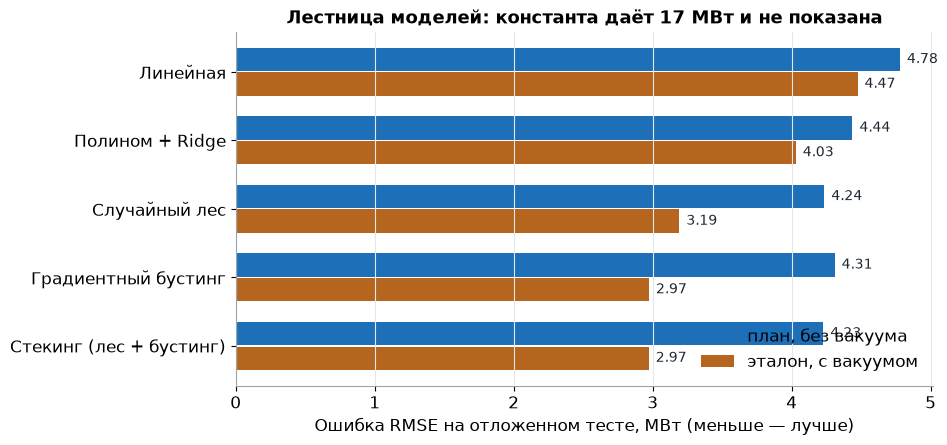

In [17]:
names = [row["name"] for row in metrics["sets"]["plan"]["test"] if row["name"] != "Константа"]
plan_rmse = {r["name"]: r["RMSE"] for r in metrics["sets"]["plan"]["test"]}
ref_rmse = {r["name"]: r["RMSE"] for r in metrics["sets"]["ref"]["test"]}
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(names))
ax.barh(y - 0.18, [plan_rmse[n] for n in names], height=0.34, color=PLAN, label="план, без вакуума")
ax.barh(y + 0.18, [ref_rmse[n] for n in names], height=0.34, color=REF, label="эталон, с вакуумом")
for i, n in enumerate(names):
    ax.text(plan_rmse[n] + 0.05, i - 0.18, f"{plan_rmse[n]:.2f}", va="center", fontsize=10, color=INK)
    ax.text(ref_rmse[n] + 0.05, i + 0.18, f"{ref_rmse[n]:.2f}", va="center", fontsize=10, color=INK)
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Ошибка RMSE на отложенном тесте, МВт (меньше — лучше)")
ax.set_title("Лестница моделей: константа даёт 17 МВт и не показана")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
save(fig, "models_ladder")
plt.show()

In [18]:
plan_info, ref_info = metrics["sets"]["plan"], metrics["sets"]["ref"]
gain = 1 - ref_info["interval"]["test_metrics"]["RMSE"] / plan_info["interval"]["test_metrics"]["RMSE"]
failed = {name: [r["name"] for r in metrics["sets"][name]["cv"] if not r["physics_ok"]] for name in ("plan", "ref")}


def physics_note(info: dict) -> str:
    physics = info["physics"]
    if physics["kept"]:
        return "оставлены"
    if not physics["physics_ok"]:
        return "не оставлены: модель с ними местами растёт с жарой"
    return "не оставлены: выигрыш меньше 1%"


lines = [
    f"- **Вакуум снижает ошибку на {gain:.0%}**, но на завтра его нет — поэтому для заявки нужна отдельная модель без него.",
    f"- Физическую проверку (мощность не растёт с жарой) не прошли: в плане — {', '.join(failed['plan']) or 'никто'}, в эталоне — {', '.join(failed['ref']) or 'никто'}. Они в выбор не попадают (решение 15 журнала).",
    f"- Среди прошедших правило выбрало: план — **{plan_info['chosen']}**, эталон — **{ref_info['chosen']}**.",
    "- Ориентир — статья авторов датасета (Tüfekci, 2014): лучшая модель MAE 2.82, RMSE 3.79 МВт. Протокол у них другой (5×2 CV, обучение на половине данных), поэтому сравниваем только по порядку величины.",
    f"- Физические признаки (плотность влажного воздуха, точка росы): RMSE плана {plan_info['physics']['rmse_base']:.3f} → {plan_info['physics']['rmse_physics']:.3f} ({physics_note(plan_info)}), эталона {ref_info['physics']['rmse_base']:.3f} → {ref_info['physics']['rmse_physics']:.3f} ({physics_note(ref_info)}). Правило: выигрыш хотя бы 1% и физика на сетке срезов, подробнее в разделе 8.1.",
]
display(Markdown("\n".join(lines)))

- **Вакуум снижает ошибку на 31%**, но на завтра его нет — поэтому для заявки нужна отдельная модель без него.
- Физическую проверку (мощность не растёт с жарой) не прошли: в плане — Полином + Ridge, Случайный лес, Стекинг (лес + бустинг), в эталоне — Полином + Ridge, Случайный лес, Стекинг (лес + бустинг). Они в выбор не попадают (решение 15 журнала).
- Среди прошедших правило выбрало: план — **Градиентный бустинг**, эталон — **Градиентный бустинг**.
- Ориентир — статья авторов датасета (Tüfekci, 2014): лучшая модель MAE 2.82, RMSE 3.79 МВт. Протокол у них другой (5×2 CV, обучение на половине данных), поэтому сравниваем только по порядку величины.
- Физические признаки (плотность влажного воздуха, точка росы): RMSE плана 4.416 → 4.346 (не оставлены: модель с ними местами растёт с жарой), эталона 3.168 → 3.167 (не оставлены: модель с ними местами растёт с жарой). Правило: выигрыш хотя бы 1% и физика на сетке срезов, подробнее в разделе 8.1.

### 3.1 Ловушка с листами в цифрах

Случайный лес, тест 20%: склеили 5 листов — RMSE 0.28 МВт, честно — 3.45 МВт


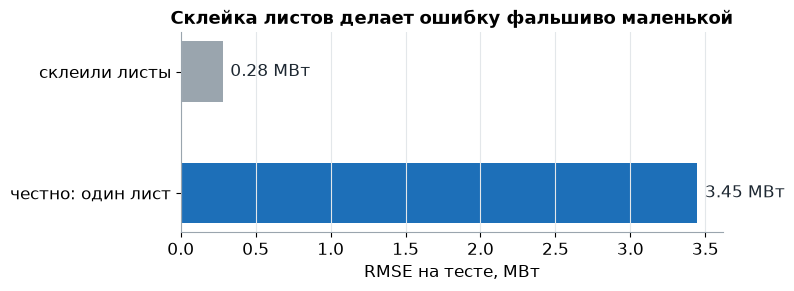

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split


def forest_rmse(frame: pd.DataFrame) -> float:
    x, y = frame[list(config.FEATURES_ALL)], frame["PE"]
    x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=config.SEED)
    model = RandomForestRegressor(n_estimators=100, random_state=config.SEED, n_jobs=-1).fit(x_tr, y_tr)
    return float(np.sqrt(np.mean((y_te - model.predict(x_te)) ** 2)))


glued_rmse, honest_rmse = forest_rmse(glued.round(4)), forest_rmse(df)
print(f"Случайный лес, тест 20%: склеили 5 листов — RMSE {glued_rmse:.2f} МВт, честно — {honest_rmse:.2f} МВт")
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh([1, 0], [glued_rmse, honest_rmse], color=[NEUTRAL, PLAN], height=0.5)
ax.set_yticks([1, 0], ["склеили листы", "честно: один лист"])
for value, pos in ((glued_rmse, 1), (honest_rmse, 0)):
    ax.text(value + 0.05, pos, f"{value:.2f} МВт", va="center", color=INK)
ax.set_xlabel("RMSE на тесте, МВт")
ax.set_title("Склейка листов делает ошибку фальшиво маленькой")
ax.grid(axis="y", visible=False)
save(fig, "trap")
plt.show()

Склеенный тест почти целиком состоит из строк, которые модель уже видела при обучении, — отсюда «точность», которой на новых данных не будет.

In [20]:
from sklearn.base import clone

from powerplant.data import split_holdout
from powerplant.models import build_ladder, build_stacking, with_physics

split = split_holdout(df, stratify_bins=10)  # то же разбиение, что в обучении
tuned = json.loads((config.MODELS_DIR / "tuned_params.json").read_text())["params"]


def tuned_model(set_name: str, name: str):
    """Необученная модель лестницы с подобранными параметрами — для разделов ниже."""
    if name.endswith(" + физика"):
        return with_physics(tuned_model(set_name, name.removesuffix(" + физика")))
    features = config.FEATURES_PLAN if set_name == "plan" else config.FEATURES_ALL
    ladder = {c.name: c for c in build_ladder(config.SEED, features=features)}
    if name.startswith("Стекинг"):
        return build_stacking(tuned_model(set_name, "Случайный лес"), tuned_model(set_name, "Градиентный бустинг"), config.SEED)
    return clone(ladder[name].estimator).set_params(**tuned[set_name].get(name, {}))

### 3.2 Сравнение со статьёй по её протоколу

Авторы датасета сравнивали модели проверкой 5×2: на каждом из пяти листов обучение на одной половине и проверка на другой, и наоборот — 10 измерений. Повторяем этот протокол для выбранного эталона на тех же листах. Это только сравнение: на выбор модели оно не влияло (выбор сделан раньше по CV).

In [21]:
ref_template = tuned_model("ref", metrics["sets"]["ref"]["chosen"])
maes, rmses = [], []
for frame in sheets.values():
    half = len(frame) // 2
    for train_part, test_part in ((frame.iloc[:half], frame.iloc[half:]), (frame.iloc[half:], frame.iloc[:half])):
        model = clone(ref_template).fit(train_part[list(config.FEATURES_ALL)], train_part["PE"])
        error = test_part["PE"].to_numpy() - model.predict(test_part[list(config.FEATURES_ALL)])
        maes.append(np.mean(np.abs(error)))
        rmses.append(np.sqrt(np.mean(error ** 2)))
paper_table = pd.DataFrame({
    "MAE, МВт": [np.mean(maes), 2.818], "RMSE, МВт": [np.mean(rmses), 3.787],
}, index=[f"наш эталон ({metrics['sets']['ref']['chosen'].lower()}), 5×2", "статья: Bagging REP Tree, 5×2"]).round(3)
display(paper_table)
paper_result = {"mae": float(np.mean(maes)), "rmse": float(np.mean(rmses))}

,"MAE, МВт","RMSE, МВт"
"наш эталон (градиентный бустинг), 5×2",2.297,3.233
"статья: Bagging REP Tree, 5×2",2.818,3.787


Цифры статьи — из вторичного источника (обзор PMC10558780). Внутри одного листа есть 41 дубль, при делении пополам часть из них попадает в обе половины — у нас и у авторов одинаково.

## 4. Что сильнее всего влияет на мощность

Три способа, не зависящих от выбранной модели:
1. **Перестановочная важность** на валидационных частях фолдов: насколько вырастает ошибка, если перемешать значения параметра. AT и V связаны, поэтому пара {AT, V} перемешивается и вместе.
2. **Графики частичной зависимости** — форма и знак влияния.
3. **Коэффициенты линейной модели** на стандартизированных признаках.

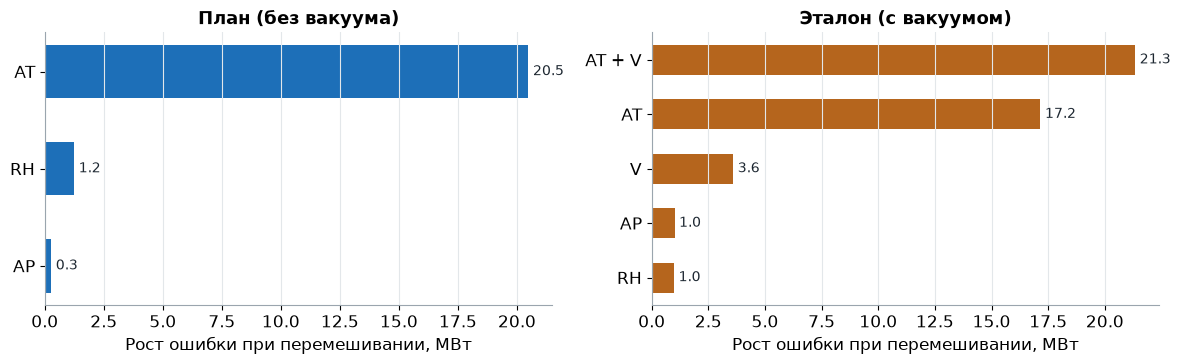

,параметр,"рост ошибки, МВт",разброс
0,AT,20.48,0.43
1,RH,1.24,0.10
2,AP,0.27,0.04


,параметр,"рост ошибки, МВт",разброс
0,AT + V,21.34,0.32
1,AT,17.16,0.32
2,V,3.60,0.34
3,AP,1.01,0.09
4,RH,0.99,0.09


In [22]:
def importance_table(set_name: str) -> pd.DataFrame:
    rows = metrics["sets"][set_name]["importance"]["permutation"]
    return pd.DataFrame(rows).rename(columns={"group": "параметр", "rmse_increase": "рост ошибки, МВт", "std": "разброс"}).round(2)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, set_name, color, title in ((axes[0], "plan", PLAN, "План (без вакуума)"), (axes[1], "ref", REF, "Эталон (с вакуумом)")):
    table = importance_table(set_name).sort_values("рост ошибки, МВт")
    ax.barh(table["параметр"], table["рост ошибки, МВт"], color=color, height=0.55)
    for pos, value in enumerate(table["рост ошибки, МВт"]):
        ax.text(value + 0.2, pos, f"{value:.1f}", va="center", color=INK, fontsize=10)
    ax.set_title(title)
    ax.set_xlabel("Рост ошибки при перемешивании, МВт")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "importance")
plt.show()
display(importance_table("plan"))
display(importance_table("ref"))

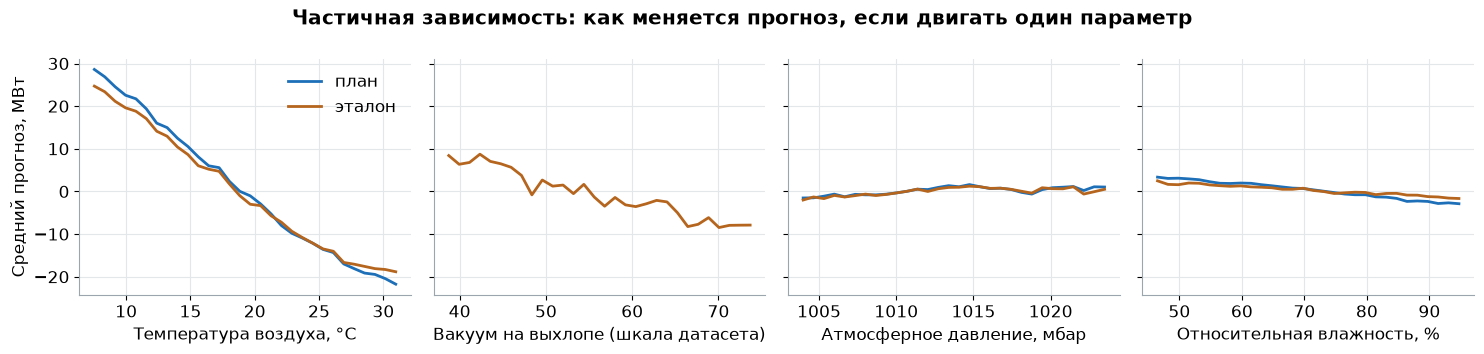

,"план, МВт на единицу","эталон, МВт на единицу","план, % мощности на единицу"
AT,-2.244,-2.008,-0.494
V,NaN,-0.500,NaN
AP,0.114,0.105,0.025
RH,-0.137,-0.077,-0.030


**Линейная модель: МВт на одно стандартное отклонение признака**

,plan,ref
AT,-17.72,-14.79
AP,0.13,0.34
RH,-2.99,-2.33
V,NaN,-2.92


In [23]:
pdp_plan, pdp_ref = metrics["sets"]["plan"]["importance"]["pdp"], metrics["sets"]["ref"]["importance"]["pdp"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, col in zip(axes, config.FEATURES_ALL, strict=True):
    if col in pdp_plan:
        ax.plot(pdp_plan[col]["grid"], pdp_plan[col]["value"], color=PLAN, linewidth=2, label="план")
    ax.plot(pdp_ref[col]["grid"], pdp_ref[col]["value"], color=REF, linewidth=2, label="эталон")
    ax.set_xlabel(config.FEATURE_LABELS[col])
axes[0].set_ylabel("Средний прогноз, МВт")
axes[0].legend(frameon=False)
fig.suptitle("Частичная зависимость: как меняется прогноз, если двигать один параметр", fontweight="bold")
fig.tight_layout()
save(fig, "pdp")
plt.show()
mean_power = df["PE"].mean()
slopes = pd.DataFrame({
    name: {col: metrics["sets"][name]["importance"]["pdp_slope_mw_per_unit"].get(col, np.nan) for col in config.FEATURES_ALL}
    for name in ("plan", "ref")
}).rename(columns={"plan": "план, МВт на единицу", "ref": "эталон, МВт на единицу"})
slopes["план, % мощности на единицу"] = slopes["план, МВт на единицу"] / mean_power * 100
display(slopes.round(3))
coefficients = pd.DataFrame({name: metrics["sets"][name]["importance"]["coefficients"] for name in ("plan", "ref")})
display(Markdown("**Линейная модель: МВт на одно стандартное отклонение признака**"))
display(coefficients.round(2))

**Физика.**
- **Температура (AT)** — главный фактор в обоих способах. Горячий воздух менее плотный, через компрессор газовой турбины проходит меньше массы, и мощность падает. В модели плана наклон по AT — полный эффект: в него входит и ухудшение охлаждения конденсатора, которое в эталоне видно через V. Наш наклон в модели плана — около 0.5% мощности на 1 °C (таблица выше). Ориентиры из литературы: 0.27% на 1 °C для одной иранской ПГУ и 0.5–0.9% для отдельной газовой турбины (низкая–средняя уверенность источника). Чувствительность зависит от конструкции станции, поэтому это ориентир, а не проверка.
- **Вакуум (V)** — второй фактор эталона: хуже вакуум → меньше перепад на паровой турбине → меньше мощность. Вместе с AT пара объясняет основную часть разброса — поэтому её важность считается и совместно.
- **Давление (AP)** — выше давление → плотнее воздух → больше мощность. Влияние небольшое, но со стабильным знаком.
- **Влажность (RH)** — вклад около 1 МВт, как у давления. При фиксированной температуре влажный воздух даёт меньше мощности (раздел 2.4): частичная зависимость и линейный коэффициент показывают тот же знак, минус.

## 5. Диапазон «от … до …»

Диапазон 90% строится по внефолдовым остаткам обучающей части (конформный подход с поправкой на конечную выборку) и проверяется на отложенном тесте. Ширина одна для всех условий, поэтому отдельно смотрим покрытие по третям AT, V и RH.

,модель,"полуширина q, МВт",покрытие на тесте,G3 (0.88–0.92)
0,план,6.91,0.908,True
1,эталон,4.65,0.911,True


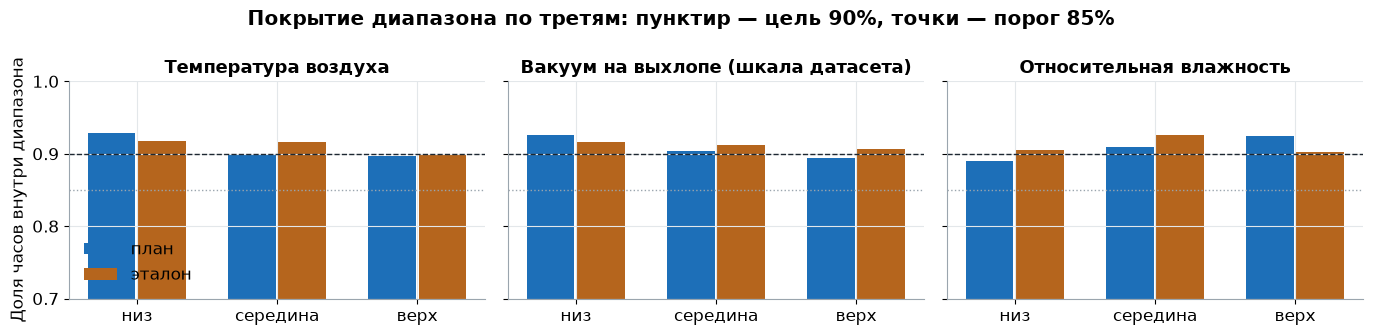

Срезы ниже 85% (G3b): нет


In [24]:
rows = []
for name, title in (("plan", "план"), ("ref", "эталон")):
    info = metrics["sets"][name]["interval"]
    rows.append({"модель": title, "полуширина q, МВт": round(info["q_mw"], 2),
                 "покрытие на тесте": round(info["coverage_test"], 3),
                 "G3 (0.88–0.92)": 0.88 <= info["coverage_test"] <= 0.92})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, ("AT", "V", "RH"), strict=True):
    for offset, name, color, title in ((-0.18, "plan", PLAN, "план"), (0.18, "ref", REF, "эталон")):
        table = pd.DataFrame(metrics["sets"][name]["interval"]["slices_test"][col])
        ax.bar(np.arange(len(table)) + offset, table["покрытие"], width=0.34, color=color, label=title)
    ax.axhline(0.9, color=INK, linewidth=1, linestyle="--")
    ax.axhline(0.85, color=NEUTRAL, linewidth=1, linestyle=":")
    ax.set_xticks(range(len(table)), table["срез"])
    ax.set_title(config.FEATURE_LABELS[col].split(",")[0])
    ax.set_ylim(0.7, 1.0)
axes[0].set_ylabel("Доля часов внутри диапазона")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Покрытие диапазона по третям: пунктир — цель 90%, точки — порог 85%", fontweight="bold")
fig.tight_layout()
save(fig, "coverage")
plt.show()
low_slices = [
    (name, col, row["срез"], round(row["покрытие"], 3))
    for name in ("plan", "ref") for col in ("AT", "V", "RH")
    for row in metrics["sets"][name]["interval"]["slices_test"][col] if row["покрытие"] < 0.85
]
print("Срезы ниже 85% (G3b):", low_slices or "нет")

Покрытие — про модель на 80% данных. Боевая модель обучена на всех строках, кроме демо-файла, и её полуширина пересчитана по внефолдовым остаткам на этих данных (поле `service` в `models/metrics.json`). Ограничения: строки считаются независимыми (времени в данных нет), а диапазон описывает ошибку модели при **точной** погоде — ошибку прогноза погоды добавляет следующий раздел.

### 5.1 Почему не интервал по деревьям леса

Популярный совет — брать 5-й и 95-й перцентили прогнозов отдельных деревьев случайного леса. Проверяем на тесте, сколько часов такой «интервал 90%» реально накрывает, и сравниваем с конформным диапазоном для того же леса.

In [25]:
from sklearn.model_selection import KFold, cross_val_predict

from powerplant.intervals import conformal_quantile

forest = tuned_model("ref", "Случайный лес")
x_tr, y_tr = split.train[list(config.FEATURES_ALL)], split.train["PE"]
x_te, y_te = split.test[list(config.FEATURES_ALL)], split.test["PE"].to_numpy()
forest.fit(x_tr, y_tr)
per_tree = np.stack([tree.predict(x_te.to_numpy()) for tree in forest.estimators_])
low, high = np.percentile(per_tree, 5, axis=0), np.percentile(per_tree, 95, axis=0)
trees_cov = np.mean((y_te >= low) & (y_te <= high))
oof = cross_val_predict(clone(forest), x_tr, y_tr, cv=KFold(5, shuffle=True, random_state=config.SEED))
q_forest = conformal_quantile(y_tr.to_numpy() - oof)
pred = forest.predict(x_te)
conf_cov = np.mean(np.abs(y_te - pred) <= q_forest)
display(pd.DataFrame({
    "покрытие на тесте": [trees_cov, conf_cov],
    "средняя ширина, МВт": [np.mean(high - low), 2 * q_forest],
}, index=["перцентили деревьев (5–95%)", "конформный, 90%"]).round(3))
trees_result = {"trees_coverage": float(trees_cov), "conformal_coverage": float(conf_cov),
                "trees_width": float(np.mean(high - low)), "conformal_width": float(2 * q_forest)}

,покрытие на тесте,"средняя ширина, МВт"
перцентили деревьев (5–95%),0.881,10.369
"конформный, 90%",0.906,10.109


Разброс между деревьями показывает неуверенность самой модели, а шум данных учитывает лишь косвенно: такой интервал накрывает меньше заявленных 90% и при этом шире. Конформный диапазон держит уровень при меньшей ширине — поэтому на странице именно он.

## 6. Стресс-тест: что будет, если ошибётся прогноз погоды

План на завтра строится по прогнозу погоды, а не по замеру. Добавляем к температуре на тесте случайную ошибку и смотрим, как растёт ошибка прогноза мощности и сужается реальное покрытие диапазона. Это синтетика для проверки устойчивости — модель на ней не учится.

,"ошибка прогноза AT, °C (σ)","MAE модели плана, МВт","MAE поправки по одной AT, МВт",покрытие диапазона
0,0.0,3.326,4.300,0.908
1,1.0,3.770,4.615,0.863
2,2.0,4.855,5.501,0.752
3,3.0,6.170,6.738,0.641


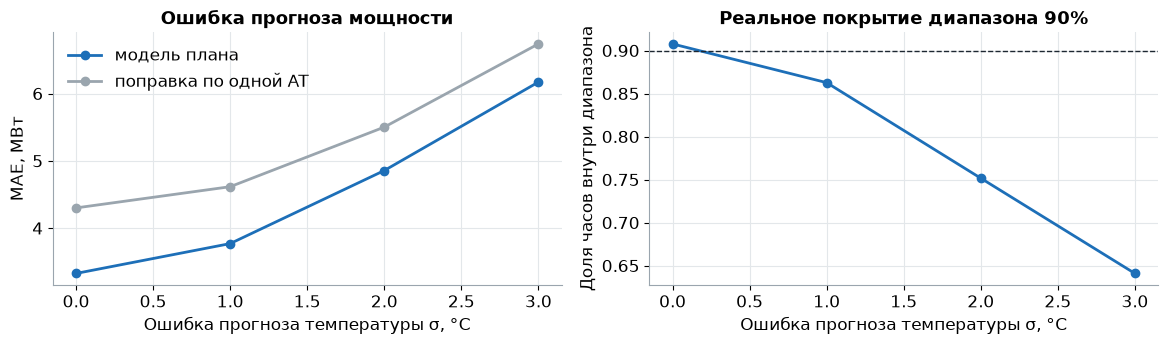

In [26]:
from sklearn.linear_model import LinearRegression

plan_model = tuned_model("plan", metrics["sets"]["plan"]["chosen"])
plan_model.fit(split.train[list(config.FEATURES_PLAN)], split.train["PE"])
base_at = LinearRegression().fit(split.train[["AT"]], split.train["PE"])  # «поправка по температуре»
q_plan = metrics["sets"]["plan"]["interval"]["q_mw"]
rng = np.random.default_rng(config.SEED)
rows = []
for sigma in (0.0, 1.0, 2.0, 3.0):
    maes, maes_base, covs = [], [], []
    for _ in range(20):
        noisy = split.test.assign(AT=split.test["AT"] + rng.normal(0, sigma, len(split.test)))
        pred = plan_model.predict(noisy[list(config.FEATURES_PLAN)])
        maes.append(np.mean(np.abs(split.test["PE"] - pred)))
        maes_base.append(np.mean(np.abs(split.test["PE"] - base_at.predict(noisy[["AT"]]))))
        covs.append(np.mean(np.abs(split.test["PE"] - pred) <= q_plan))
    rows.append({"ошибка прогноза AT, °C (σ)": sigma, "MAE модели плана, МВт": np.mean(maes),
                 "MAE поправки по одной AT, МВт": np.mean(maes_base), "покрытие диапазона": np.mean(covs)})
stress = pd.DataFrame(rows)
display(stress.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(stress.iloc[:, 0], stress.iloc[:, 1], marker="o", color=PLAN, linewidth=2, label="модель плана")
axes[0].plot(stress.iloc[:, 0], stress.iloc[:, 2], marker="o", color=NEUTRAL, linewidth=2, label="поправка по одной AT")
axes[0].set_xlabel("Ошибка прогноза температуры σ, °C")
axes[0].set_ylabel("MAE, МВт")
axes[0].set_title("Ошибка прогноза мощности")
axes[0].legend(frameon=False)
axes[1].plot(stress.iloc[:, 0], stress.iloc[:, 3], marker="o", color=PLAN, linewidth=2)
axes[1].axhline(0.9, color=INK, linestyle="--", linewidth=1)
axes[1].set_xlabel("Ошибка прогноза температуры σ, °C")
axes[1].set_ylabel("Доля часов внутри диапазона")
axes[1].set_title("Реальное покрытие диапазона 90%")
fig.tight_layout()
save(fig, "stress")
plt.show()

Чем хуже прогноз погоды, тем шире реальный разброс: в рабочем внедрении полосу для заявки нужно расширять на ошибку прогноза погоды конкретного поставщика. Модель при этом остаётся лучше простой поправки по одной температуре при любой ошибке.

## 7. Контроль оборудования: суточное правило

Одиночный час ниже нижней границы диапазона случается примерно в 5% часов и на здоровой станции — это тревога каждые сутки. Поэтому тревогу даём по среднему отклонению факта от эталона за сутки: порог выбран так, чтобы на здоровой станции срабатывал 1% суточных окон. Проверка — на искусственных поломках: к внефолдовым остаткам добавляем устойчивое падение мощности на 1, 2 и 3%.

Порог: среднее (факт − эталон) за 24 ч ниже -1.72 МВт


,доля пойманных за сутки
1%,1.0
2%,1.0
3%,1.0


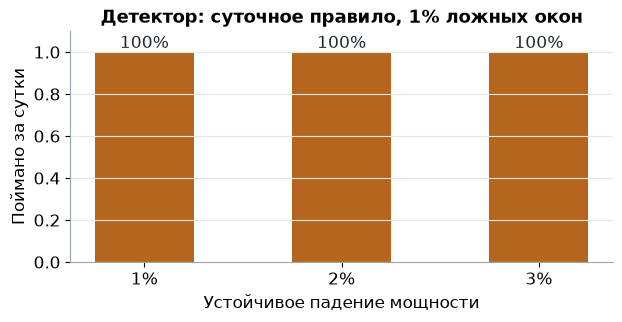

In [27]:
detector = metrics["detector"]
print(f"Порог: среднее (факт − эталон) за {detector['window_h']} ч ниже {detector['threshold_mw']:.2f} МВт")
rates = pd.Series(detector["detection_rate_by_drop"], name="доля пойманных за сутки")
display(rates.to_frame())
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(rates.index, rates.values, color=REF, width=0.5)
for pos, value in enumerate(rates.values):
    ax.text(pos, value + 0.02, f"{value:.0%}", ha="center", color=INK)
ax.set_ylim(0, 1.1)
ax.set_xlabel("Устойчивое падение мощности")
ax.set_ylabel("Поймано за сутки")
ax.set_title("Детектор: суточное правило, 1% ложных окон")
ax.grid(axis="x", visible=False)
save(fig, "detector")
plt.show()

In [28]:
from powerplant.artifact import load_bundle
from powerplant.service import ForecastService

service = ForecastService(load_bundle())
example = service.batch("example.csv", service.example_csv().encode())
s = example.summary
print(f"Демо-файл: {s.rows} ч, строки, которых модель не видела; со второй половины мощность снижена на 2%.")
print(f"Тревога с {s.first_alarm_hour}-го часа, всего {s.alarm_hours} ч; недобор {s.lost_mwh} МВт·ч.")

Демо-файл: 168 ч, строки, которых модель не видела; со второй половины мощность снижена на 2%.
Тревога с 91-го часа, всего 78 ч; недобор 828.8 МВт·ч.


In [29]:
from powerplant.detector import detection_rate

mean_power = float(df["PE"].mean())
sensitivity = pd.DataFrame([
    {"падение, %": share * 100, "падение, МВт": share * mean_power,
     "поймано за сутки": detection_rate(service.bundle.reference.residuals, 24,
                                        service.bundle.detector_threshold, -share * mean_power)}
    for share in (0.002, 0.003, 0.004, 0.005, 0.0075, 0.01)
])
display(Markdown("**Чувствительность: какое падение правило замечает за сутки**"))
display(sensitivity.round(3))

**Чувствительность: какое падение правило замечает за сутки**

,"падение, %","падение, МВт",поймано за сутки
0,0.20,0.909,0.085
1,0.30,1.363,0.252
2,0.40,1.817,0.545
3,0.50,2.272,0.817
4,0.75,3.408,0.998
5,1.00,4.543,1.000


Ограничения: окна собраны из независимых остатков, реальные часы связаны между собой — на живом потоке ложных тревог будет больше; «прочее» включает и ошибку самого эталона, поэтому тревога — сигнал проверить оборудование, а не диагноз.

## 8. Проверка решений, которых нет в кейсе

Кейс просит прогноз мощности по параметрам и ответ, что влияет сильнее всего. Четыре вещи мы добавили сами, и каждую проверяем на тех же отложенных данных:

1. **План на завтра без вакуума.** Завтрашний вакуум никто не знает. Нужно показать две вещи: вакуум действительно добавляет точности, а попытка спрогнозировать его по погоде ничего не даёт.
2. **Разложение недобора на «вакуум» и «прочее».** Разность «эталон − план» должна отражать именно вакуум.
3. **Предупреждение о новизне.** Флаг должен стоять там, где данных нет и ответ модели нечем проверить.
4. **Риск не выполнить план.** Заявленная вероятность недобора должна совпадать с наблюдаемой.

Модели сравниваем парно: обе предсказывают одни и те же часы теста, модули ошибок сравниваем парным t-тестом и, для надёжности, критерием Уилкоксона. Вторая проверка — 5×2 на пяти листах авторов с t-тестом Диттериха (1998): он учитывает, что половины одного листа зависимы.

In [30]:
from sklearn.model_selection import KFold, cross_val_predict

from powerplant.evidence import (
    VacuumFromWeather, calibration_table, dietterich_5x2cv, novelty_error_ratio, paired_error_test,
)
from powerplant.models import FRESH_FOLD_OFFSET
from powerplant.novelty import fit_novelty, novelty_distance


def ru(value: float, digits: int = 2) -> str:
    return f"{value:.{digits}f}".replace(".", ",").replace("-", "−")


def p_text(p: float) -> str:
    return "p < 0,001" if p < 0.001 else f"p = {ru(p, 3)}"


P, A = list(config.FEATURES_PLAN), list(config.FEATURES_ALL)
train, test = split.train, split.test
y_test = test["PE"].to_numpy()
plan_fit = tuned_model("plan", metrics["sets"]["plan"]["chosen"]).fit(train[P], train["PE"])
ref_fit = tuned_model("ref", metrics["sets"]["ref"]["chosen"]).fit(train[A], train["PE"])
two_stage = VacuumFromWeather(power_model=tuned_model("ref", metrics["sets"]["ref"]["chosen"]))
two_stage.fit(train[A], train["PE"])
pred_plan, pred_ref = plan_fit.predict(test[P]), ref_fit.predict(test[A])
pred_two = two_stage.predict(test[P])  # только погода: вакуум берётся из её прогноза

sheet_list = list(sheets.values())
evidence = {
    "test_plan_vs_ref": paired_error_test(y_test, pred_plan, pred_ref),
    "test_plan_vs_two_stage": paired_error_test(y_test, pred_plan, pred_two),
    "cv5x2_plan_vs_ref": dietterich_5x2cv(clone(plan_fit), P, clone(ref_fit), A, sheet_list),
    "cv5x2_plan_vs_two_stage": dietterich_5x2cv(clone(plan_fit), P, two_stage, A, sheet_list),
}
pairs = {
    "план без вакуума и эталон с вакуумом": ("test_plan_vs_ref", "cv5x2_plan_vs_ref"),
    "план без вакуума и «вакуум по погоде → эталон»": ("test_plan_vs_two_stage", "cv5x2_plan_vs_two_stage"),
}
display(pd.DataFrame([{
    "сравнение": name,
    "MAE плана, МВт": evidence[t]["mae_a"],
    "MAE второй модели, МВт": evidence[t]["mae_b"],
    "t на тесте": evidence[t]["t"],
    "p на тесте": evidence[t]["p_value"],
    "p Уилкоксона": evidence[t]["wilcoxon_p"],
    "разность MAE в 5×2, МВт": evidence[cv]["mean_mae_diff"],
    "p в 5×2": evidence[cv]["p_value"],
} for name, (t, cv) in pairs.items()]).set_index("сравнение"))

,"MAE плана, МВт","MAE второй модели, МВт",t на тесте,p на тесте,p Уилкоксона,"разность MAE в 5×2, МВт",p в 5×2
сравнение,,,,,,,
план без вакуума и эталон с вакуумом,3.326,2.125,23.521,1.303e-107,8.164e-104,1.098,8.992e-07
план без вакуума и «вакуум по погоде → эталон»,3.326,3.361,-1.208,2.274e-01,1.880e-01,-0.087,1.165e-01


In [31]:
with_v, via_weather = evidence["test_plan_vs_ref"], evidence["test_plan_vs_two_stage"]
cv_v, cv_weather = evidence["cv5x2_plan_vs_ref"], evidence["cv5x2_plan_vs_two_stage"]
if via_weather["mae_b"] > via_weather["mae_a"] and via_weather["p_value"] < 0.05:
    verdict = "план не улучшает и даже немного ухудшает"
elif via_weather["p_value"] >= 0.05:
    verdict = "план значимо не улучшает"
else:
    verdict = "план улучшает — решение надо пересмотреть"
display(Markdown(
    f"**Вывод по вакууму.** Вакуум нужен: с ним средняя ошибка падает с {ru(with_v['mae_a'])} "
    f"до {ru(with_v['mae_b'])} МВт ({p_text(with_v['p_value'])} на тесте, "
    f"{p_text(cv_v['p_value'])} в проверке 5×2). "
    f"Прогноз вакуума по погоде {verdict}: {ru(via_weather['mae_b'])} против "
    f"{ru(via_weather['mae_a'])} МВт ({p_text(via_weather['p_value'])} на тесте, "
    f"{p_text(cv_weather['p_value'])} в проверке 5×2). "
    "Всё, что погода говорит о вакууме, модель плана и так берёт из самой погоды, "
    "а ошибка прогноза вакуума только добавляет шум. Поэтому в плане на завтра вакуума нет, "
    "а в контроле, где он измерен, есть."
))

**Вывод по вакууму.** Вакуум нужен: с ним средняя ошибка падает с 3,33 до 2,12 МВт (p < 0,001 на тесте, p < 0,001 в проверке 5×2). Прогноз вакуума по погоде план значимо не улучшает: 3,36 против 3,33 МВт (p = 0,227 на тесте, p = 0,117 в проверке 5×2). Всё, что погода говорит о вакууме, модель плана и так берёт из самой погоды, а ошибка прогноза вакуума только добавляет шум. Поэтому в плане на завтра вакуума нет, а в контроле, где он измерен, есть.

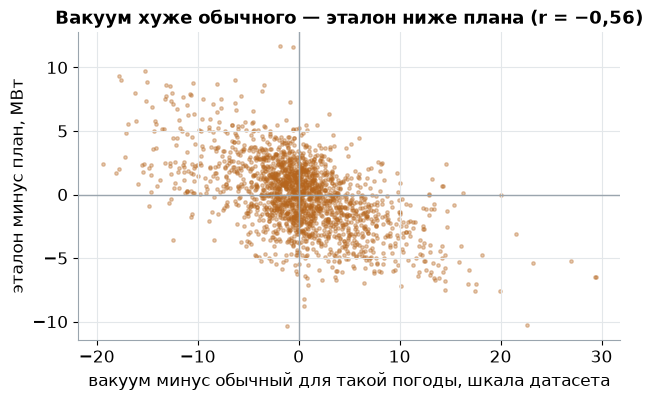

In [32]:
v_deviation = test["V"].to_numpy() - two_stage.vacuum_model_.predict(test[P])
evidence["decomposition_corr"] = float(np.corrcoef(pred_ref - pred_plan, v_deviation)[0, 1])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(v_deviation, pred_ref - pred_plan, s=6, alpha=0.35, color=REF)
ax.axhline(0, color=NEUTRAL, lw=1)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set_xlabel("вакуум минус обычный для такой погоды, шкала датасета")
ax.set_ylabel("эталон минус план, МВт")
ax.set_title(f"Вакуум хуже обычного — эталон ниже плана (r = {ru(evidence['decomposition_corr'])})")
save(fig, "decomposition")
plt.show()

Чем выше вакуум (на шкале датасета это хуже) по сравнению с обычным для такой погоды, тем ниже эталон относительно плана. Это проверка согласованности, а не независимое доказательство: разница «эталон − план» по построению зависит от вакуума. Важно другое: связь идёт в физически верную сторону и заметна на фоне ошибок обеих моделей, значит, раскладывать по ней недобор осмысленно. Связь не стопроцентная, в разнице есть и ошибки моделей, поэтому «прочее» — сигнал проверить оборудование, а не диагноз.

In [33]:
novelty = fit_novelty(train[A])
test_flags = novelty_distance(novelty, test[A]) > novelty.threshold
evidence["novelty"] = novelty_error_ratio(y_test - pred_ref, test_flags)

ladder_names = ["Линейная", "Полином + Ridge", "Случайный лес", "Градиентный бустинг"]
ladder_fits = [tuned_model("ref", name).fit(train[A], train["PE"]) for name in ladder_names]


def disagreement(points: pd.DataFrame) -> np.ndarray:
    predictions = np.stack([model.predict(points[A]) for model in ladder_fits])
    return predictions.max(axis=0) - predictions.min(axis=0)


rng = np.random.default_rng(config.SEED)
box = pd.DataFrame({c: rng.uniform(config.INPUT_RANGES[c].low, config.INPUT_RANGES[c].high, 20_000) for c in A})
box_flags = novelty_distance(novelty, box) > novelty.threshold
groups = {
    "тест, без флага": disagreement(test[A][~test_flags]),
    "тест, с флагом": disagreement(test[A][test_flags]),
    "любые значения ползунков, без флага": disagreement(box[~box_flags]),
    "любые значения ползунков, с флагом": disagreement(box[box_flags]),
}
display(Markdown("**Насколько расходятся четыре модели лестницы**, обученные на одних и тех же данных"))
display(pd.DataFrame({
    "точек": {k: len(v) for k, v in groups.items()},
    "медиана расхождения, МВт": {k: np.median(v) for k, v in groups.items()},
    "90-й перцентиль, МВт": {k: np.percentile(v, 90) for k, v in groups.items()},
}).round(1))

hot = df[df["AT"] > 30][A].median()
unseen = pd.DataFrame([{**hot.to_dict(), "AT": 33.0, "V": 38.0}])  # сценарий «Небывалое сочетание» на странице
unseen_predictions = {name: float(model.predict(unseen[A])[0]) for name, model in zip(ladder_names, ladder_fits, strict=True)}
evidence["novelty_disagreement"] = {
    "test_median_mw": float(np.median(groups["тест, без флага"])),
    "flagged_median_mw": float(np.median(groups["любые значения ползунков, с флагом"])),
    "unseen_point_mw": unseen_predictions,
}
display(pd.Series(unseen_predictions, name="прогноз при жаре 33 °C и вакууме 38, МВт").round(1).to_frame())

**Насколько расходятся четыре модели лестницы**, обученные на одних и тех же данных

,точек,"медиана расхождения, МВт","90-й перцентиль, МВт"
"тест, без флага",1892,3.1,5.6
"тест, с флагом",14,4.1,7.2
"любые значения ползунков, без флага",243,3.3,6.1
"любые значения ползунков, с флагом",19757,55.7,895.8


,"прогноз при жаре 33 °C и вакууме 38, МВт"
Линейная,434.4
Полином + Ridge,414.1
Случайный лес,445.3
Градиентный бустинг,436.4


In [34]:
nov, spread = evidence["novelty"], evidence["novelty_disagreement"]
display(Markdown(
    f"**Вывод по новизне.** На тесте флаг сработал в {nov['n_flagged']} часах из {len(test)} "
    f"({ru(nov['n_flagged'] / len(test) * 100, 1)}%), и ошибка эталона на них не выше обычной "
    f"({ru(nov['mae_flagged'])} против {ru(nov['mae_rest'])} МВт): тест лежит внутри данных, "
    "и флаг почти не шумит. Его работа — зона без данных. Там четыре модели, которые на тесте почти "
    f"не расходятся (медиана разброса {ru(spread['test_median_mw'], 1)} МВт), расходятся с медианой "
    f"{ru(spread['flagged_median_mw'], 1)} МВт, и проверить, какая права, нечем: таких часов в данных нет. "
    f"Пример — жара 33 °C при вакууме 38: модели дают от {ru(min(spread['unseen_point_mw'].values()), 0)} "
    f"до {ru(max(spread['unseen_point_mw'].values()), 0)} МВт. Поэтому в этой зоне страница предупреждает, "
    "а не выдаёт уверенную цифру."
))

**Вывод по новизне.** На тесте флаг сработал в 14 часах из 1906 (0,7%), и ошибка эталона на них не выше обычной (1,93 против 2,13 МВт): тест лежит внутри данных, и флаг почти не шумит. Его работа — зона без данных. Там четыре модели, которые на тесте почти не расходятся (медиана разброса 3,1 МВт), расходятся с медианой 55,7 МВт, и проверить, какая права, нечем: таких часов в данных нет. Пример — жара 33 °C при вакууме 38: модели дают от 414 до 445 МВт. Поэтому в этой зоне страница предупреждает, а не выдаёт уверенную цифру.

In [35]:
oof = cross_val_predict(clone(plan_fit), train[P], train["PE"],
                        cv=KFold(config.CV_FOLDS, shuffle=True, random_state=config.SEED + FRESH_FOLD_OFFSET))
calibration = calibration_table(y_test, pred_plan, train["PE"].to_numpy() - oof)
evidence["calibration"] = calibration.to_dict(orient="records")
display(calibration.rename(columns={"заявлено": "риск недобора, который обещает модель",
                                    "наблюдалось": "доля недоборов на тесте"}).round(3))

,"риск недобора, который обещает модель",доля недоборов на тесте
0,0.05,0.046
1,0.10,0.108
2,0.25,0.249
3,0.50,0.506


Риск откалиброван: когда модель обещает «вероятность не выдать объём 10%», на тесте так и выходит — недобор примерно в каждом десятом часе. Значит, цифре риска на странице можно верить.

### 8.1 Плотность воздуха и точка росы: проверили и не взяли

Плотность влажного воздуха и точку росы считаем по формулам из тех же температуры, давления и влажности, новой информации в них нет: они только помогают деревьям уловить нелинейные сочетания погоды. Правило одно для обеих моделей: признаки остаются, если модель с ними не нарушает физику на сетке срезов и её RMSE на кросс-валидации падает хотя бы на 1%. Сравниваем три варианта модели плана: без признаков, с признаками без ограничений и с признаками, ограниченными по физике (больше плотность — больше мощность, выше точка росы — меньше мощность).

In [36]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline

from powerplant.features import PhysicsFeatures, air_density, dew_point

plan_base = tuned_model("plan", "Градиентный бустинг")
physics_folds = KFold(config.CV_FOLDS, shuffle=True, random_state=config.SEED + FRESH_FOLD_OFFSET)
plan_novelty = fit_novelty(train[P])


def physics_pipeline(constraints: dict) -> Pipeline:
    return Pipeline([("physics", PhysicsFeatures()), ("model", clone(plan_base).set_params(monotonic_cst=constraints))])


def rising_steps(model) -> tuple[int, int]:
    grid = np.linspace(train["AT"].min(), train["AT"].max(), 40)
    inside = outside = 0
    for ap in train["AP"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]):
        for rh in train["RH"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]):
            frame = pd.DataFrame({"AT": grid, "AP": ap, "RH": rh})
            steps = np.diff(model.predict(frame[P]))
            novel = novelty_distance(plan_novelty, frame) > plan_novelty.threshold
            for i, step in enumerate(steps):
                if step > config.PHYSICS_TOLERANCE_MW:
                    if novel[i] or novel[i + 1]:
                        outside += 1
                    else:
                        inside += 1
    return inside, outside


variants = {
    "без признаков": clone(plan_base),
    "с признаками без ограничений": physics_pipeline({"AT": -1}),
    "с признаками и ограничениями по физике": physics_pipeline({"AT": -1, "density": 1, "dew_point": -1}),
}
rows = {}
for name, model in variants.items():
    oof = cross_val_predict(clone(model), train[P], train["PE"], cv=physics_folds)
    inside, outside = rising_steps(clone(model).fit(train[P], train["PE"]))
    rows[name] = {"RMSE на CV, МВт": float(np.sqrt(np.mean((train["PE"] - oof) ** 2))),
                  "рост с жарой в данных": inside, "рост с жарой вне данных": outside}
physics_table = pd.DataFrame(rows).T
base_rmse = physics_table.loc["без признаков", "RMSE на CV, МВт"]
physics_table["выигрыш, %"] = (base_rmse - physics_table["RMSE на CV, МВт"]) / base_rmse * 100
display(Markdown("**Модель плана с физическими признаками и без них.** Рост с жарой — число шагов сетки, где мощность растёт больше чем на 0,5 МВт (25 срезов по давлению и влажности)."))
display(physics_table.round(3))

engineered = train[P].assign(density=air_density(train["AT"], train["AP"], train["RH"]),
                             dew_point=dew_point(train["AT"], train["RH"]))
vacuum_rmse = {}
for name, cols in (("AT, AP, RH", P), ("+ точка росы", P + ["dew_point"])):
    prediction = cross_val_predict(HistGradientBoostingRegressor(random_state=config.SEED), engineered[cols], train["V"], cv=physics_folds)
    vacuum_rmse[name] = float(np.sqrt(np.mean((train["V"] - prediction) ** 2)))
evidence["physics"] = {"table": physics_table.to_dict(orient="index"), "vacuum_rmse": vacuum_rmse}

**Модель плана с физическими признаками и без них.** Рост с жарой — число шагов сетки, где мощность растёт больше чем на 0,5 МВт (25 срезов по давлению и влажности).

,"RMSE на CV, МВт",рост с жарой в данных,рост с жарой вне данных,"выигрыш, %"
без признаков,4.416,0.0,0.0,0.000
с признаками без ограничений,4.346,12.0,21.0,1.607
с признаками и ограничениями по физике,4.398,0.0,0.0,0.418


In [37]:
free = physics_table.loc["с признаками без ограничений"]
constrained = physics_table.loc["с признаками и ограничениями по физике"]
display(Markdown(
    f"**Вывод.** Без ограничений признаки снижают ошибку плана на {ru(free['выигрыш, %'], 1)}%, но модель тогда местами растёт с жарой: "
    f"{int(free['рост с жарой в данных'])} шагов внутри данных и {int(free['рост с жарой вне данных'])} вне их. "
    f"С ограничениями по физике роста нет, но и выигрыш падает до {ru(constrained['выигрыш, %'], 1)}%, это ниже нашего порога в 1%. "
    "Поэтому обе модели обходятся без этих признаков, а физическую проверку при выборе модели мы делаем на сетке срезов. "
    f"Точка росы при этом помогает угадывать вакуум по погоде (RMSE {ru(vacuum_rmse['AT, AP, RH'], 2)} → {ru(vacuum_rmse['+ точка росы'], 2)}): "
    "во влажную погоду охлаждение конденсатора хуже. Это объяснение, а не доказанный факт, тип охлаждения станции в данных не указан."
))

**Вывод.** Без ограничений признаки снижают ошибку плана на 1,6%, но модель тогда местами растёт с жарой: 12 шагов внутри данных и 21 вне их. С ограничениями по физике роста нет, но и выигрыш падает до 0,4%, это ниже нашего порога в 1%. Поэтому обе модели обходятся без этих признаков, а физическую проверку при выборе модели мы делаем на сетке срезов. Точка росы при этом помогает угадывать вакуум по погоде (RMSE 5,49 → 5,36): во влажную погоду охлаждение конденсатора хуже. Это объяснение, а не доказанный факт, тип охлаждения станции в данных не указан.

### 8.2 Плотность: Менделеев–Клапейрон или Ван-дер-Ваальс

Плотность влажного воздуха считаем по уравнению Менделеева–Клапейрона, то есть как для идеального газа, для смеси сухого воздуха и пара. Уравнение Ван-дер-Ваальса учитывает размер молекул и их притяжение и точнее при высоком давлении и около конденсации. Проверяем, сколько оно меняет при атмосферном давлении и температурах из данных и меняет ли что-то в модели.

In [38]:
from scipy import stats

from powerplant.features import air_density_van_der_waals

ideal_all = air_density(df["AT"], df["AP"], df["RH"])
real_all = air_density_van_der_waals(df["AT"], df["AP"], df["RH"])
correction = (real_all / ideal_all - 1) * 100


def plan_cv_rmse(density_formula) -> float:
    frame = train[P].assign(density=density_formula(train["AT"], train["AP"], train["RH"]),
                            dew_point=dew_point(train["AT"], train["RH"]))
    prediction = cross_val_predict(clone(plan_base), frame, train["PE"], cv=physics_folds)
    return float(np.sqrt(np.mean((train["PE"].to_numpy() - prediction) ** 2)))


eos = {
    "density_range_pct": float((ideal_all.max() / ideal_all.min() - 1) * 100),
    "correction_min_pct": float(correction.min()),
    "correction_max_pct": float(correction.max()),
    "spearman": float(stats.spearmanr(ideal_all, real_all).statistic),
    "cv_rmse_ideal": plan_cv_rmse(air_density),
    "cv_rmse_vdw": plan_cv_rmse(air_density_van_der_waals),
}
evidence["equation_of_state"] = eos
display(pd.DataFrame({"значение": {
    "размах плотности в данных, %": eos["density_range_pct"],
    "поправка Ван-дер-Ваальса, мин., %": eos["correction_min_pct"],
    "поправка Ван-дер-Ваальса, макс., %": eos["correction_max_pct"],
    "корреляция Спирмена двух плотностей": eos["spearman"],
    "RMSE модели плана на CV, Менделеев–Клапейрон": eos["cv_rmse_ideal"],
    "RMSE модели плана на CV, Ван-дер-Ваальс": eos["cv_rmse_vdw"],
}}).round(7))
display(Markdown(
    f"**Вывод.** Ван-дер-Ваальс поправил бы плотность на {ru(eos['correction_min_pct'], 2)}–"
    f"{ru(eos['correction_max_pct'], 2)}%, а сама плотность в данных меняется на {ru(eos['density_range_pct'], 1)}%. "
    f"Порядок значений тот же (корреляция Спирмена {ru(eos['spearman'], 7)}), и ошибка варианта модели плана с плотностью не меняется: "
    f"{ru(eos['cv_rmse_ideal'], 4)} против {ru(eos['cv_rmse_vdw'], 4)} МВт на CV. По справочным данным расчёт "
    "плотности влажного воздуха как идеального газа ошибается меньше чем на 0,2% от −10 до 50 °C. Ван-дер-Ваальс "
    "нужен при высоком давлении и около конденсации, а на входе в компрессор атмосферный воздух. Поэтому оставляем "
    "Менделеева–Клапейрона: проще, а точнее модель не станет. Давление насыщенного пара считаем по формуле Магнуса, "
    "это стандартное приближение уравнения Клаузиуса–Клапейрона для пара над водой."
))
(ROOT / "reports" / "evidence.json").write_text(json.dumps(evidence, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("Результаты проверок сохранены: reports/evidence.json")

,значение
"размах плотности в данных, %",15.786
"поправка Ван-дер-Ваальса, мин., %",0.056
"поправка Ван-дер-Ваальса, макс., %",0.090
корреляция Спирмена двух плотностей,1.000
"RMSE модели плана на CV, Менделеев–Клапейрон",4.346
"RMSE модели плана на CV, Ван-дер-Ваальс",4.348


**Вывод.** Ван-дер-Ваальс поправил бы плотность на 0,06–0,09%, а сама плотность в данных меняется на 15,8%. Порядок значений тот же (корреляция Спирмена 0,9999996), и ошибка варианта модели плана с плотностью не меняется: 4,3455 против 4,3480 МВт на CV. По справочным данным расчёт плотности влажного воздуха как идеального газа ошибается меньше чем на 0,2% от −10 до 50 °C. Ван-дер-Ваальс нужен при высоком давлении и около конденсации, а на входе в компрессор атмосферный воздух. Поэтому оставляем Менделеева–Клапейрона: проще, а точнее модель не станет. Давление насыщенного пара считаем по формуле Магнуса, это стандартное приближение уравнения Клаузиуса–Клапейрона для пара над водой.

Результаты проверок сохранены: reports/evidence.json


## 9. Экономика внедрения

Считаем по шаблону ментора: простои, цена часа простоя, сокращение простоев, затраты на внедрение и сопровождение → экономия после сопровождения и срок окупаемости. Формулы те же, что в шаблоне. На его собственном примере (16 ч, 5 000 ₽/ч, 25%, 60 000 ₽ и 2 000 ₽/мес) код даёт те же 18 000 ₽/мес и 3,3 месяца, это закреплено тестом.

**Что считаем простоем.** Аварийные остановы мы не прогнозируем и в расчёт не берём. Считаем недобор мощности, который на фоне погоды не виден, и переводим его в эквивалентные часы простоя: 1% мощности за 100 часов — один час полного простоя. Главная причина накопленных потерь газовой турбины — загрязнение компрессора, на него приходится 70–85% потерь; при умеренном загрязнении турбина теряет до 5% мощности к 8 000 часов работы (Meher-Homji, Bromley, Stalder, 2013). Детектор замечает такой недобор раньше, и станция раньше промывает компрессор или ищет причину.

**Объект** — ПГУ-450 Ярославской ТЭС, 463,9 МВт: станция того же масштаба, что в данных (420–496 МВт). Из них 313,9 МВт дают две газовые турбины ГТЭ-160. Компрессор есть только у них, поэтому недобор считаем только с их мощности. Паровая часть при загрязнении тоже теряет, но её мы не учитываем, и оценка выходит осторожнее. Источник каждой цифры — в `reports/economics.xlsx`, допущения там отмечены.

In [39]:
from dataclasses import asdict, replace

from powerplant.economics import (
    PlantAssumptions, breakeven_reduction, cumulative_result, downtime_economics, vacuum_loss_profile,
)

PRICE = config.PRICE_RUB_PER_MWH
plant = PlantAssumptions()
inputs = plant.to_inputs()
result = downtime_economics(inputs)


def money(value: float) -> str:
    return f"{value:,.0f}".replace(",", " ")


display(Markdown("**Исходные данные**"))
display(pd.DataFrame({
    "значение": [ru(inputs.downtime_hours_per_month), money(inputs.cost_per_hour_rub),
                 ru(inputs.reduction_share * 100, 0), money(inputs.implementation_rub),
                 money(inputs.support_rub_per_month)],
    "ед. изм.": ["экв. ч/мес", "₽/ч", "%", "₽", "₽/мес"],
    "откуда": [f"{ru(plant.gas_turbines_mw, 1)} МВт ГТУ × {plant.fouling_loss_at_8000h:.0%} × {ru(plant.average_loss_ratio, 1)} / {ru(plant.plant_mw, 1)} МВт × 730 ч",
               f"{ru(plant.plant_mw, 1)} МВт × {money(PRICE)} ₽/МВт·ч",
               "допущение: осторожная оценка",
               f"{plant.implementation_person_days:g} чел.-дней × 8 ч × {money(plant.hourly_rate_rub())} ₽/ч",
               f"сервер {money(plant.server_rub_per_month)} ₽ + {plant.support_hours_per_month:g} ч поддержки"],
}, index=["Простои оборудования за месяц", "Стоимость одного часа простоя", "Предполагаемое сокращение простоев",
          "Затраты на внедрение программы", "Расходы на сопровождение программы"]))
display(Markdown("**Расчёт экономии**"))
display(pd.DataFrame({"значение": [money(result.loss_rub_per_month), ru(result.hours_saved_per_month),
                                   money(result.saving_rub_per_month), money(result.net_saving_rub_per_month),
                                   money(result.net_saving_rub_per_year), money(result.first_year_result_rub),
                                   ru(result.payback_months, 1)],
                      "ед. изм.": ["₽/мес", "ч/мес", "₽/мес", "₽/мес", "₽", "₽", "мес"]},
                     index=["Потери от простоев сейчас", "На сколько сократятся простои",
                            "Экономия от сокращения простоев", "Экономия после расходов на сопровождение",
                            "Экономия за 12 месяцев", "Результат за первый год", "Срок окупаемости"]))

**Исходные данные**

,значение,ед. изм.,откуда
Простои оборудования за месяц,"12,35",экв. ч/мес,"313,9 МВт ГТУ × 5% × 0,5 / 463,9 МВт × 730 ч"
Стоимость одного часа простоя,810 433,₽/ч,"463,9 МВт × 1 747 ₽/МВт·ч"
Предполагаемое сокращение простоев,1,%,допущение: осторожная оценка
Затраты на внедрение программы,307 570,₽,20 чел.-дней × 8 ч × 1 922 ₽/ч
Расходы на сопровождение программы,13 527,₽/мес,сервер 5 838 ₽ + 4 ч поддержки


**Расчёт экономии**

,значение,ед. изм.
Потери от простоев сейчас,10 007 995,₽/мес
На сколько сократятся простои,"0,12",ч/мес
Экономия от сокращения простоев,100 080,₽/мес
Экономия после расходов на сопровождение,86 553,₽/мес
Экономия за 12 месяцев,1 038 632,₽
Результат за первый год,731 062,₽
Срок окупаемости,"3,6",мес


In [40]:
reductions, factors = (0.01, 0.05, 0.10, 0.25), (1, 3, 10)
sensitivity_grid = pd.DataFrame(
    {f"внедрение ×{f}": [downtime_economics(replace(inputs, reduction_share=share,
                                                    implementation_rub=inputs.implementation_rub * f)).payback_months
                          for share in reductions] for f in factors},
    index=[f"сокращение {share:.0%}" for share in reductions]).round(1)
display(Markdown("**Срок окупаемости, месяцев: сокращение простоев × затраты на внедрение**"))
display(sensitivity_grid)
breakeven = breakeven_reduction(inputs)
display(Markdown(
    f"Программа окупится за год уже при сокращении простоев на {ru(breakeven * 100)}%: это "
    f"{ru(inputs.downtime_hours_per_month * breakeven * 60, 1)} минуты работы станции на полной мощности в месяц. "
    f"Даже если внедрение обойдётся вдесятеро дороже, при сокращении на 5% оно окупится за "
    f"{ru(sensitivity_grid.loc['сокращение 5%', 'внедрение ×10'], 1)} месяца."
))

**Срок окупаемости, месяцев: сокращение простоев × затраты на внедрение**

,внедрение ×1,внедрение ×3,внедрение ×10
сокращение 1%,3.6,10.7,35.5
сокращение 5%,0.6,1.9,6.3
сокращение 10%,0.3,0.9,3.1
сокращение 25%,0.1,0.4,1.2


Программа окупится за год уже при сокращении простоев на 0,39%: это 2,9 минуты работы станции на полной мощности в месяц. Даже если внедрение обойдётся вдесятеро дороже, при сокращении на 5% оно окупится за 6,3 месяца.

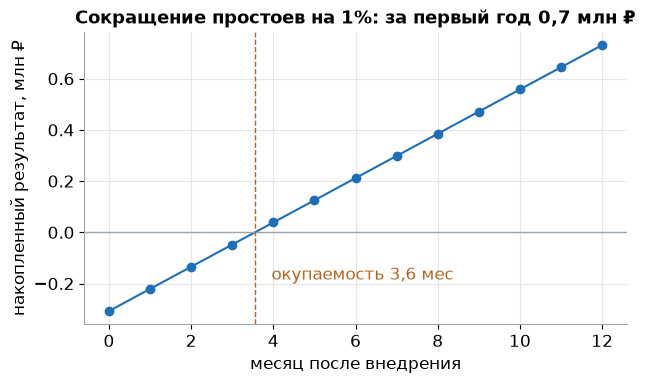

In [41]:
curve = np.array(cumulative_result(inputs, 12)) / 1e6
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(range(13), curve, marker="o", color=PLAN)
ax.axhline(0, color=NEUTRAL, lw=1)
ax.axvline(result.payback_months, color=REF, ls="--", lw=1)
ax.annotate(f"окупаемость {ru(result.payback_months, 1)} мес", (result.payback_months, 0),
            xytext=(result.payback_months + 0.4, curve.min() * 0.6), color=REF)
ax.set_xlabel("месяц после внедрения")
ax.set_ylabel("накопленный результат, млн ₽")
ax.set_title(f"Сокращение простоев на {plant.reduction_share:.0%}: за первый год "
             f"{ru(result.first_year_result_rub / 1e6, 1)} млн ₽")
save(fig, "payback")
plt.show()

In [42]:
profile = vacuum_loss_profile(pred_plan, pred_ref, worst_share=0.1)
display(Markdown(
    "**Сверху, в окупаемость не входит.** "
    f"В {profile['share_hours_worse']:.0%} часов теста вакуум хуже обычного для такой погоды и отнимает в среднем "
    f"{ru(profile['mean_loss_when_worse_mw'], 1)} МВт, в 10% худших часов — {ru(profile['worst_mean_loss_mw'], 1)} МВт. "
    "Точнее заявка на рынок на сутки вперёд (режим плана) тоже приносит деньги, но долю потерь на отклонениях "
    "мы в открытых источниках не нашли, поэтому в рубли этот эффект не переводим."
))

**Сверху, в окупаемость не входит.** В 51% часов теста вакуум хуже обычного для такой погоды и отнимает в среднем 2,3 МВт, в 10% худших часов — 5,1 МВт. Точнее заявка на рынок на сутки вперёд (режим плана) тоже приносит деньги, но долю потерь на отклонениях мы в открытых источниках не нашли, поэтому в рубли этот эффект не переводим.

In [43]:
def finite(value: float) -> float | None:
    return float(value) if np.isfinite(value) else None


summary = {
    "trap": {"glued_rmse": glued_rmse, "honest_rmse": honest_rmse},
    "stress": stress.to_dict(orient="records"),
    "vacuum": profile,
    "price": PRICE,
    "economics": {
        "plant_mw": plant.plant_mw,
        "reduction_share": plant.reduction_share,
        "inputs": asdict(inputs),
        "result": {k: finite(v) for k, v in asdict(result).items()},
        "breakeven_reduction": breakeven,
        "curve_rub": cumulative_result(inputs, 12),
        "scenarios": {f"{share:.0%}": {k: finite(v) for k, v in asdict(
            downtime_economics(replace(inputs, reduction_share=share))).items()} for share in reductions},
        "sensitivity": {col: [finite(v) for v in sensitivity_grid[col]] for col in sensitivity_grid.columns},
    },
    "evidence": evidence,
    "vacuum_units": vacuum_units,
    "demo": {"rows": s.rows, "first_alarm_hour": s.first_alarm_hour, "alarm_hours": s.alarm_hours},
    "paper": paper_result,
    "trees": trees_result,
    "detector_sensitivity": sensitivity.to_dict(orient="records"),
}
(ROOT / "reports" / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("Сводка для слайдов сохранена: reports/summary.json")

Сводка для слайдов сохранена: reports/summary.json


**Как читать.** Наши собственные цифры — модели, их точность и порог детектора. В рубли их переводят цифры из открытых источников (мощность станции и её газовых турбин, цена РСВ, загрязнение компрессора, зарплата разработчика, сервер) и допущения: средний недобор за цикл, работа на полной нагрузке весь месяц, сокращение простоев, трудоёмкость внедрения и часы поддержки. Самое спорное из них — сокращение простоев, поэтому мы берём осторожный 1% и показываем таблицей, что будет при других значениях и при более дорогом внедрении. Решающую роль играет масштаб станции: час её работы на полной мощности стоит дороже, чем всё внедрение по нашей оценке.